# Fig. 1: simulated Visium-like slide with the null model

EnrichMap with the null model (default since 0.3.0) and with smoothing only, against AUCell, GSVA, ssGSEA,
Z score, Scanpy and GSDensity, on the simulated slide of 05_00_simulated_dataset (seed 0, cluster_2 signature).
Panels: 1b maps and recovery of cluster 2, 1c Moran's I and Geary's C, 1d variograms, 1e Moran scatter,
1f-h gene contributions. Source data are saved as CSV next to each figure.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import gseapy as gp
import decoupler as dc
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns

from adjustText import adjust_text
from enrichmap.plotting._morans_correlogram import _quadrant_style
from esda.moran import Moran
from libpysal.weights import KNN
from libpysal.weights.spatial_lag import lag_spatial
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.spatial import KDTree
from scipy.spatial.distance import pdist
from skgstat import Variogram
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, average_precision_score

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)

# processed data directory
processed_data = project_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
    "AUCell": "#86bf6e",
    "GSVA": "#c76663",
    "ssGSEA": "#8f6eb0",
    "Z score": "#866342",
    "Scanpy": "#cf83bd",
    "GSDensity": "#e3a33b",
}
methods = list(colours)
spot_size = 30

In [6]:
from helpers import (
    simulate_visium_fig1,
    plot_metric_pair_points,
    plot_scaled_metric_dot_summary,
    plot_method_variograms,
    contribution_heatmap_matrix,
    set_box_ratio,
)

In [7]:
# 1. Simulated Visium dataset (05_00_simulated_dataset)
# 2. Simulate the slide (the generator normalises once, as in the published panels)
adata, sig_genes, fold_changes, target_label = simulate_visium_fig1(seed=0)
adata.obs["cluster"] = pd.Categorical(adata.obs["cluster"])
coords = adata.obsm["spatial"]
# is_target = (adata.obs["cluster"] == target_label).values
# prevalence = is_target.mean()

In [8]:
# 3. EnrichMap: null model (default) and smoothing-only
variants = {
    "null": dict(compute_q_vals=True),
    "smooth": dict(null_model=False),
}

for name, kwargs in variants.items():
    em.tl.score(adata, gene_set=sig_genes, score_key=f"{target_label}_{name}", n_neighbors=6, **kwargs)

# null-model diagnostics (one batch)
# null = adata.uns["null_model"][f"{target_label}_null"]
# print(pd.Series({
#     "mean level offset":float(np.ravel(null["mean_level_offset"])[0]),
#     "level offset / median null SD": null["level_offset_ratio"],
#     "control overlap (mean Jaccard)": null["control_overlap"],
#     "weights refitted": null["weights_refitted"],
#     "spots with z = 0": int((adata.obs[f"{target_label}_null_score"] == 0).sum()),
# }).to_string())

Scoring cluster_2_smooth: 20/20 genes found: 100%|██████████| 1/1 [00:00<00:00, 21.49it/s]


In [9]:
# 4. Comparators: AUCell and Scanpy (05_00_simulated_dataset)
# convert the signature dict to a long format
signatures_dict = {"cluster_2": sig_genes}

signatures = pd.DataFrame(
    [(key, gene) for key, genes in signatures_dict.items() for gene in genes],
    columns=["source", "target"],
)

dc.mt.aucell(adata, net=signatures)
score_aucell = dc.pp.get_obsm(adata=adata, key="score_aucell")
adata.obs["aucell_score"] = score_aucell.obsm["score_aucell"]

sc.tl.score_genes(adata, sig_genes, score_name="scanpy_score", use_raw=False)

In [10]:
# ssGSEA, GSVA and Z score
X_dense = adata.X.toarray() if not isinstance(adata.X, np.ndarray) else adata.X

# Create DataFrame using var names as columns and obs names as index
gene_expr = pd.DataFrame(X_dense.T, index=adata.var_names, columns=adata.obs_names)

gene_expr.index = gene_expr.index.str.upper()
signatures_dict = {k: [g.upper() for g in v] for k, v in signatures_dict.items()}

ssgsea = gp.ssgsea(
    data=gene_expr,
    gene_sets=signatures_dict,
    outdir=None,
    sample_norm_method="rank",
    no_plot=True,
    min_size=2
)

nes = ssgsea.res2d.pivot(index="Term", columns="Name", values="NES")
adata.obs["ssgsea_score"] = nes.loc["cluster_2"].T.astype(float).reindex(adata.obs_names)

gsva = gp.gsva(
    data=gene_expr,
    gene_sets=signatures_dict,
    outdir=None,
    min_size=2
)
es = gsva.res2d.pivot(index="Term", columns="Name", values="ES")
adata.obs["gsva_score"] = es.loc["cluster_2"].T.astype(float).reindex(adata.obs_names)

gene_set = signatures_dict["cluster_2"]
z_score = gene_expr.loc[gene_set].sum(axis=0) / np.sqrt(len(gene_set))
adata.obs["z_score"] = z_score

In [11]:
# 5. GSDensity relevance (R package, run in its own environment; read from the cache), shown as relevance x spots
gsd_dir = working_dir + "data/gsd_cache/sims/"
gsd = pd.read_csv(gsd_dir + "Fig1_seed000_cluster_2.csv", index_col=0)
gsd = gsd.reindex(adata.obs_names)
adata.obs["gsdensity_score"] = gsd["relevance_scaled"].values
gsd_positive = (gsd["label"] == "positive").values

# GSDensity's own spatial test of the gene set (spatial KLD vs 100 coordinate shuffles)
gsd_kld = pd.read_csv(gsd_dir + "_tasks/Fig1_seed000/gsd_spatial_kld.csv", index_col=0)

# score column of each method
method_keys = {
    "EnrichMap (null)": f"{target_label}_null_score",
    "AUCell": "aucell_score",
    "GSVA": "gsva_score",
    "ssGSEA": "ssgsea_score",
    "Z score": "z_score",
    "Scanpy": "scanpy_score",
    "GSDensity": "gsdensity_score",
}
methods = list(method_keys)
scores = pd.DataFrame({m: adata.obs[k].values for m, k in method_keys.items()}, index=adata.obs_names)

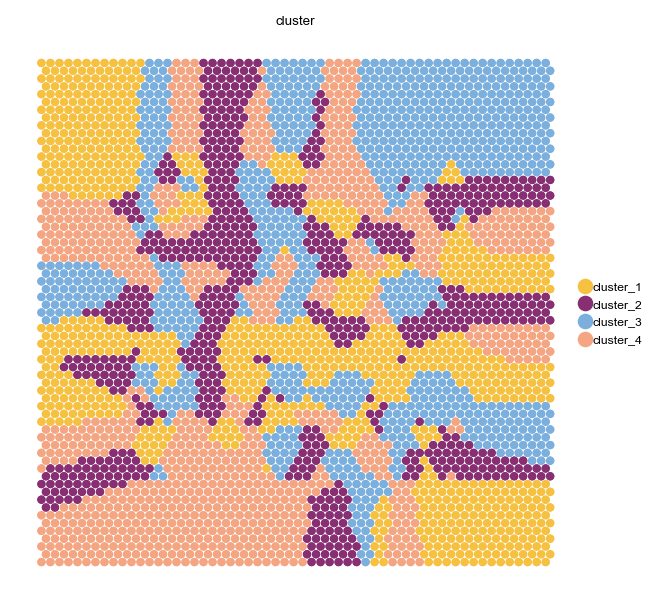

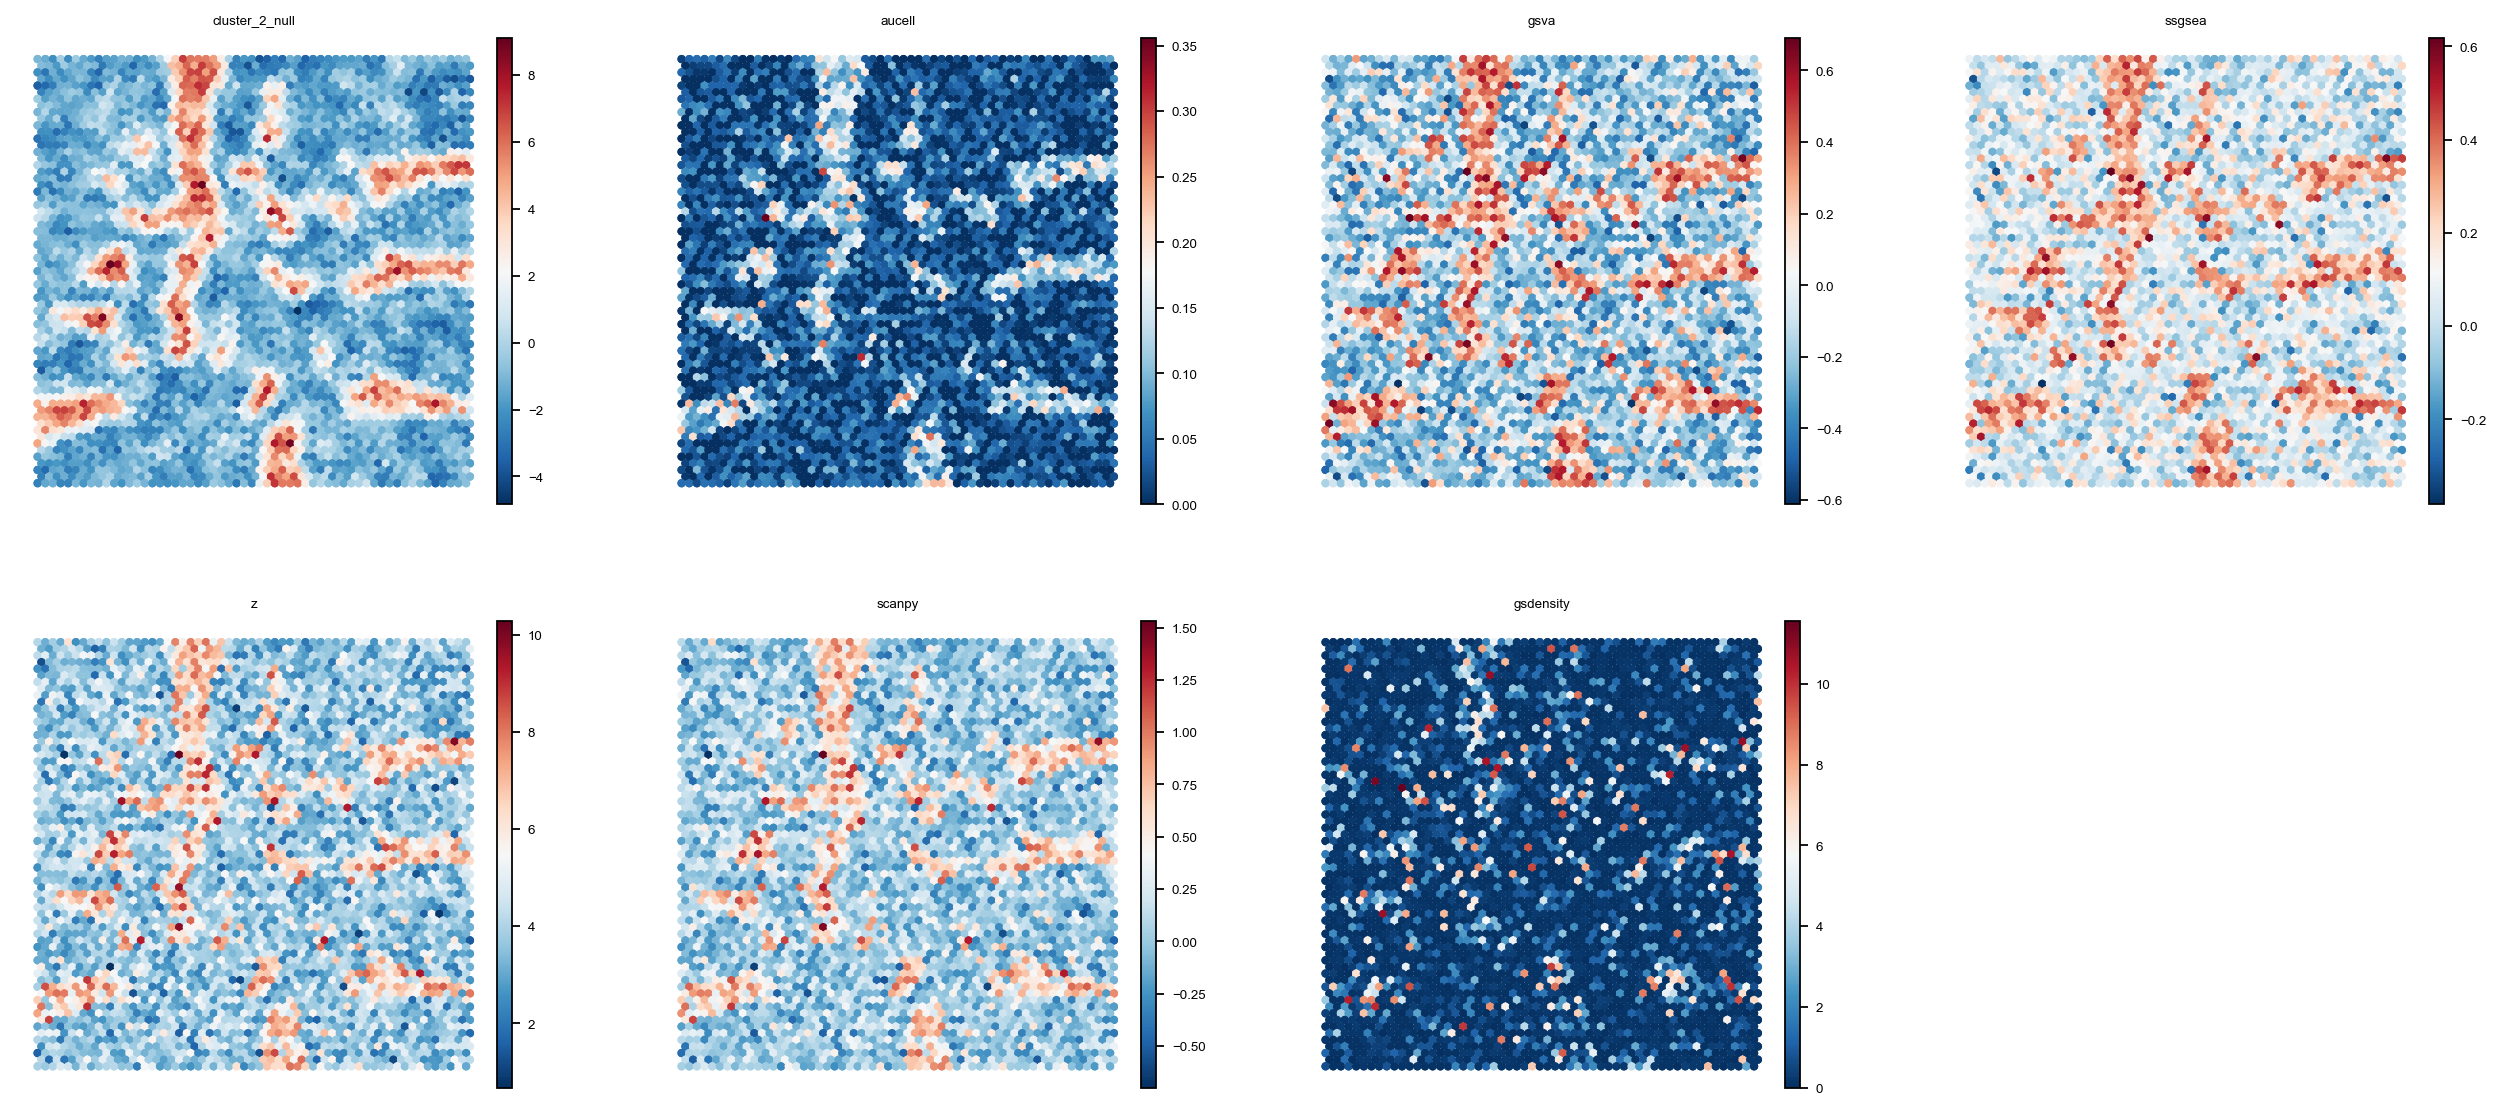

In [12]:
# 6. Fig. 1b: simulated clusters (05_00_simulated_dataset) and score maps, centred at 0 and uncentred
cluster_palettes = {
    "cluster_1": "#F6C141",
    "cluster_2": "#882E72",
    "cluster_3": "#7BAFDE",
    "cluster_4": "#F4A582"
}

# Convert 'cluster' column to categorical dtype
adata.obs["cluster"] = pd.Categorical(adata.obs["cluster"])

# Now you can access the categories
clusters = adata.obs["cluster"].cat.categories

# Reorder the palette list to match the category order
palette_list = [cluster_palettes[c] for c in clusters]

# Create a ListedColormap
cmap = ListedColormap(palette_list)

sq.pl.spatial_scatter(
    adata,
    color="cluster",
    img_alpha=0,
    size=spot_size,
    shape=None,
    palette=cmap,
    save="Fig1b_clusters.pdf",
)

clusters_df = pd.DataFrame(
    {"x": coords[:, 0], "y": coords[:, 1], "cluster": adata.obs["cluster"].values},
    index=adata.obs_names,
)
clusters_df.to_csv(source_dir + "Fig1b_clusters.csv")

keys = list(method_keys.values())

em.pl.spatial_enrichmap(
    adata,
    score_key=keys,
    vcenter=None,
    ncols=4,
    save=f"Fig1b_score_maps.pdf",
    shape=None,
    size=spot_size,
)

maps = adata.obs[keys].copy()
maps.insert(0, "y", coords[:, 1])
maps.insert(0, "x", coords[:, 0])
maps.to_csv(source_dir + "Fig1b_score_maps.csv")

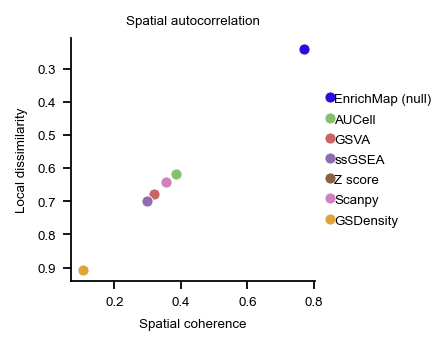

In [13]:
# 8. Fig. 1c: Moran's I and Geary's C
summary_rows = []
for m, key in method_keys.items():
    np.random.seed(0)
    metrics, _ = em.tl.compute_spatial_metrics(adata, score_key=key, n_neighbors=6)
    summary_rows.append(
        {
            "method": m,
            "Spatial coherence": metrics["Moran's I"],
            "Local dissimilarity": metrics["Geary's C"],
        }
    )

autocorrelation = pd.DataFrame(summary_rows)

fig, ax = plt.subplots(figsize=(2, 2))

plot_metric_pair_points(
    ax, autocorrelation, "Spatial coherence", "Local dissimilarity", colours, invert_y=True
)

# Set all dots to 1 mm diameter with no outlines
diameter_pt = 72 / 25.4  # 1 mm in points

for collection in ax.collections:
    collection.set_sizes([diameter_pt**2])
    collection.set_linewidths(0)
    collection.set_edgecolors("none")

ax.set_title("Spatial autocorrelation")
ax.legend(
    frameon=False,
    fontsize=6,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    handletextpad=0.1,
)
sns.despine(ax=ax)
ax.set_box_aspect(1)

plt.savefig(figure_dir + "Fig1c_moran_geary.pdf", bbox_inches="tight")
plt.show()

autocorrelation.to_csv(source_dir + "Fig1c_moran_geary.csv", index=False)

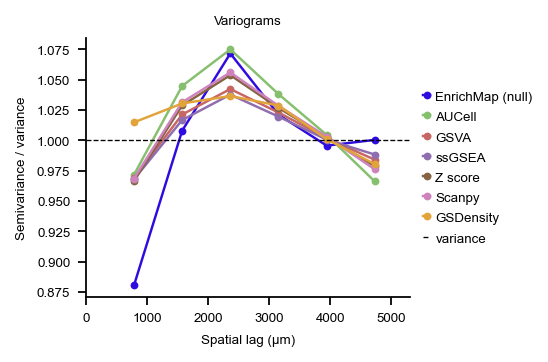

In [14]:
# 9. Fig. 1d: experimental variograms (as em.pl.variogram_all: skgstat, cressie estimator, 10 lag bins)
max_lag = np.percentile(pdist(coords), 95)

variogram_rows = []
for m in methods:
    values = scores[m].values
    V = Variogram(coords, values, method="cressie", model="gaussian", verbose=False)
    for i, (lag, gamma, n_pairs) in enumerate(zip(V.bins, V.experimental, V.bin_count)):
        variogram_rows.append({
            "method": m,
            "bin": i + 1,
            "spatial_lag_upper_edge_um": lag,
            "semivariance": gamma,
            "n_pairs": int(n_pairs),
            "variance": np.var(values),
            "semivariance_over_variance": gamma / np.var(values),
            "inside_plotted_x_range": lag <= max_lag,
        })
variogram_df = pd.DataFrame(variogram_rows)

variogram_handles = [Line2D([0], [0], color=colours[m], marker="o", markersize=2.5, lw=1.1, label=m)
                     for m in methods]

# compact panel: semivariance relative to each score's variance (all methods on one scale)
fig, ax = plt.subplots(figsize=(2.6, 2.2))
plot_method_variograms(ax, variogram_df, methods, colours, max_lag, "semivariance_over_variance")
ax.set_ylabel("Semivariance / variance")
ax.set_title("Variograms")
handles = variogram_handles + [Line2D([0], [0], color="black", lw=0.6, ls="--", label="variance")]
ax.legend(handles=handles, frameon=False, fontsize=6, loc="center left", bbox_to_anchor=(1.02, 0.5))
set_box_ratio(fig)
plt.savefig(figure_dir + "Fig1d_variograms.pdf", bbox_inches="tight")
plt.show()
variogram_df.to_csv(source_dir + "Fig1d_variograms.csv", index=False)

`em.pl.morans_correlogram` splits the quadrants at 0. That is meaningful for the null model (0 = matched random
gene sets), so it keeps the package rule. The other scores have no common zero (the smoothing-only score, AUCell,
Z score and GSDensity are positive everywhere), so their quadrants are split at the slide mean, as in the classical
Moran scatter plot of centred values. Moran's *I* does not depend on the split.

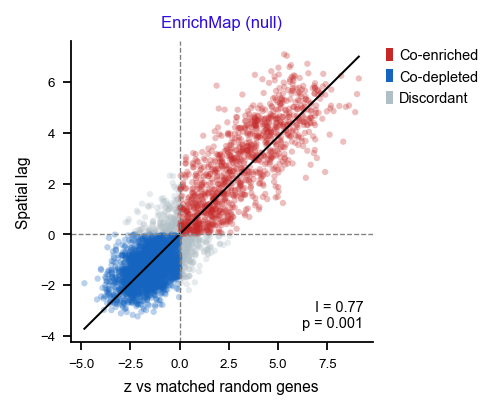

In [15]:
# 10. Fig. 1e: Moran scatter for EnrichMap (null) only
m = "EnrichMap (null)"

W6 = KNN.from_array(coords, k=6)
W6.transform = "r"

q_colours, q_labels = _quadrant_style(1.0)

# Compute Moran's I and spatial lag
score = scores[m].values

np.random.seed(0)
moran = Moran(score, W6, permutations=999)

score_lag = lag_spatial(W6, score)
cut = 0.0

# Quadrants (split at zero)
quadrants = np.full(len(score), "LL", dtype=object)
quadrants[(score >= cut) & (score_lag >= cut)] = "HH"
quadrants[(score >= cut) & (score_lag < cut)] = "HL"
quadrants[(score < cut) & (score_lag >= cut)] = "LH"

# Regression line
slope, intercept = np.polyfit(score, score_lag, 1)

# Statistics
moran_df = pd.DataFrame(
    [
        {
            "method": m,
            "Moran's I (6-NN, row-standardised)": moran.I,
            "expected I under randomisation": moran.EI,
            "pseudo p-value (999 permutations)": moran.p_sim,
            "z (permutation)": moran.z_sim,
            "regression slope": slope,
            "regression intercept": intercept,
            "quadrant split": "0",
            "split value": cut,
            "co-enriched (HH)": np.mean(quadrants == "HH"),
            "co-depleted (LL)": np.mean(quadrants == "LL"),
            "discordant (HL, LH)": np.mean(np.isin(quadrants, ["HL", "LH"])),
        }
    ]
)

# Single-panel scatter plot
fig, ax = plt.subplots(figsize=(3, 3))

# Exactly 1 mm marker diameter, no outline
dot_size = (72 / 25.4) ** 2

for q in ["LH", "HL", "LL", "HH"]:
    mask = quadrants == q

    ax.scatter(
        score[mask],
        score_lag[mask],
        s=dot_size,
        alpha=0.3,
        color=q_colours[q],
        edgecolors="none",
        linewidths=0,
    )

# Regression line
x_line = np.array([score.min(), score.max()])
ax.plot(x_line, slope * x_line + intercept, color="black", lw=0.9)

# Quadrant boundaries
ax.axhline(cut, color="grey", lw=0.6, ls="--")
ax.axvline(cut, color="grey", lw=0.6, ls="--")

# Moran's I annotation
ax.text(
    0.97,
    0.04,
    f"I = {moran.I:.2f}\np = {moran.p_sim:.3f}",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=6.5,
)

# Formatting
ax.set_title(m, fontsize=7.5, color=colours[m])
ax.set_xlabel("z vs matched random genes", fontsize=7)
ax.set_ylabel("Spatial lag", fontsize=7)
ax.tick_params(labelsize=6)
ax.set_box_aspect(1)
ax.grid(False)

sns.despine(ax=ax)

# Legend
handles = [Patch(facecolor=q_colours[q], label=q_labels[q]) for q in ["HH", "LL", "LH"]]

ax.legend(
    handles=handles,
    frameon=False,
    fontsize=6.5,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
)

plt.tight_layout()

plt.savefig(figure_dir + "Fig1e_moran_scatter.pdf", bbox_inches="tight")

plt.show()

# Export source data
scatter_df = pd.DataFrame(index=adata.obs_names)
scatter_df[f"{m}: score"] = score
scatter_df[f"{m}: spatial lag"] = score_lag
scatter_df[f"{m}: quadrant"] = quadrants

scatter_df.to_csv(source_dir + "Fig1e_moran_scatter.csv")
moran_df.to_csv(source_dir + "Fig1e_moran_statistics.csv", index=False)

Heatmap genes (top 5 by mean |contribution|): ['GENE_01710', 'GENE_02417', 'GENE_01959', 'GENE_00690', 'GENE_00579']; clusters: ['cluster_1', 'cluster_3', 'cluster_4', 'cluster_2']; colour limit +/- 2.421


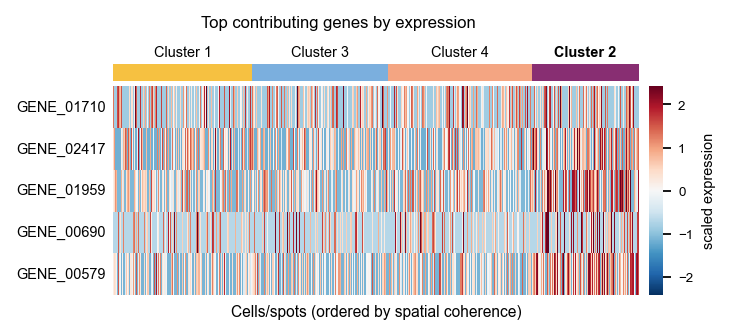

In [16]:
# 11. Fig. 1f: gene contribution heatmap (contributions = log-expression x CV weight, the same for both variants)
contributions = adata.uns["gene_contributions"][f"{target_label}_null"]

cluster_labels = adata.obs["cluster"].astype(str).values
heat, heat_genes, heat_spots, mean_abs = contribution_heatmap_matrix(contributions, coords, top_n_genes=5, groupby=cluster_labels)
heat_vmax = np.nanpercentile(np.abs(heat), 99)
cluster_order = list(dict.fromkeys(cluster_labels))
print(f"Heatmap genes (top 5 by mean |contribution|): {heat_genes}; clusters: {cluster_order}; "
      f"colour limit +/- {heat_vmax:.3f}")

fig = plt.figure(figsize=(4.4, 1.9))
gs = fig.add_gridspec(2, 2, height_ratios=[0.08, 1], width_ratios=[1, 0.025], hspace=0.05, wspace=0.04)
ax_group = fig.add_subplot(gs[0, 0])
ax_heat = fig.add_subplot(gs[1, 0])
cax = fig.add_subplot(gs[1, 1])
start = 0
for grp in cluster_order:
    n = int(np.sum(cluster_labels == grp))
    ax_group.axvspan(start, start + n, color=cluster_palettes[grp], lw=0)
    ax_group.text(start + n / 2, 1.3, grp.replace("cluster_", "Cluster "), ha="center", va="bottom", fontsize=6.5,
                  fontweight="bold" if grp == target_label else "normal")
    start += n
ax_group.set_xlim(0, adata.n_obs)
ax_group.set_ylim(0, 1)
ax_group.axis("off")
sns.heatmap(
    heat, cmap="RdBu_r", center=0, vmin=-heat_vmax, vmax=heat_vmax, yticklabels=heat_genes, xticklabels=False,
    ax=ax_heat, cbar_ax=cax, cbar_kws={"label": "scaled expression"},
)
ax_heat.set_xlabel("Cells/spots (ordered by spatial coherence)", fontsize=7)
ax_heat.tick_params(axis="y", labelsize=6.5, length=0)
cax.tick_params(labelsize=6)
cax.yaxis.label.set_fontsize(6.5)
fig.suptitle("Top contributing genes by expression", fontsize=7.5, y=1.07)
set_box_ratio(fig, axes=[ax_heat])
plt.savefig(figure_dir + "Fig1f_gene_contributions.pdf", bbox_inches="tight")
plt.show()

heat_df = pd.DataFrame({
    "row_position": np.repeat(np.arange(1, len(heat_genes) + 1), heat.shape[1]),
    "gene": np.repeat(heat_genes, heat.shape[1]),
    "column_position": np.tile(np.arange(1, heat.shape[1] + 1), len(heat_genes)),
    "spot_id": np.tile(adata.obs_names[heat_spots], len(heat_genes)),
    "cluster": np.tile(cluster_labels[heat_spots], len(heat_genes)),
    "scaled_contribution": heat.ravel(),
    "contribution": np.concatenate([np.asarray(contributions[g])[heat_spots] for g in heat_genes]),
})
heat_df.to_csv(source_dir + "Fig1f_gene_contributions.csv", index=False)

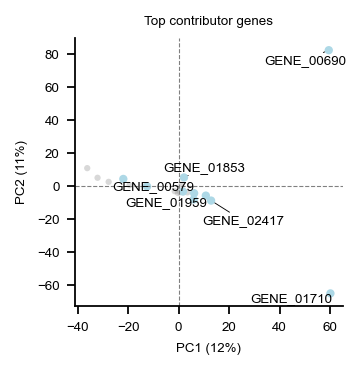

In [17]:
# 12. Fig. 1g: PCA of the gene contribution vectors (as em.pl.gene_contributions_pca, top_n_genes=10)
# exact SVD: PC1 and PC2 explain almost the same variance, so the randomized solver is unstable here
gene_names = list(contributions.keys())
Xc = np.vstack([contributions[g] for g in gene_names])
pca = PCA(n_components=2, svd_solver="full")
pcs = pca.fit_transform(Xc)
norms = np.linalg.norm(Xc, axis=1)
top10 = set(np.array(gene_names)[np.argsort(norms)[-10:]])
top6 = list(np.array(gene_names)[np.argsort(norms)[::-1][:6]])
weights = em.tl.infer_gene_weights(adata, gene_names)

pca_df = pd.DataFrame({
    "gene": gene_names,
    "PC1": pcs[:, 0],
    "PC2": pcs[:, 1],
    "contribution_norm": norms,
    "mean_abs_contribution": [mean_abs[g] for g in gene_names],
    "cv_weight": [weights[g] for g in gene_names],
    "true_fold_change": [fold_changes[sig_genes.index(g)] for g in gene_names],
    "top10_by_norm_highlighted": [g in top10 for g in gene_names],
    "labelled (six largest norms)": [g in top6 for g in gene_names],
}).sort_values("contribution_norm", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(2.3, 2.2))
other = ~pca_df["top10_by_norm_highlighted"]
ax.scatter(pca_df.loc[other, "PC1"], pca_df.loc[other, "PC2"], s=8, color="grey", alpha=0.3, edgecolors="none")
ax.scatter(pca_df.loc[~other, "PC1"], pca_df.loc[~other, "PC2"], s=14, color="lightblue", edgecolors="none")
texts = [
    ax.text(r["PC1"], r["PC2"], r["gene"], fontsize=6, ha="center", va="center")
    for _, r in pca_df[pca_df["labelled (six largest norms)"]].iterrows()
]
ax.axhline(0, color="grey", ls="--", lw=0.5)
ax.axvline(0, color="grey", ls="--", lw=0.5)
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="black", lw=0.4))
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Top contributor genes")
ax.grid(False)
sns.despine(ax=ax)
set_box_ratio(fig, ratio=1)
plt.savefig(figure_dir + "Fig1g_gene_contribution_pca.pdf", bbox_inches="tight")
plt.show()
pca_df.to_csv(source_dir + "Fig1g_gene_contribution_pca.csv", index=False)

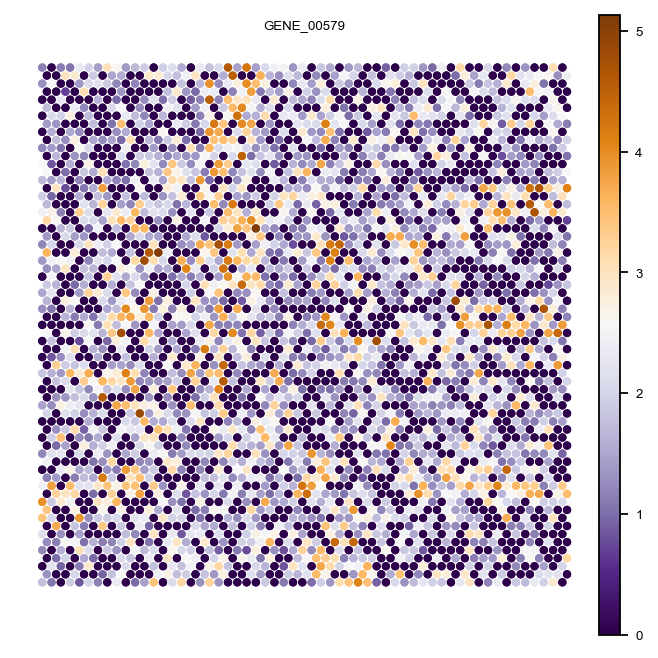

In [18]:
# 13. Fig. 1h: spatial expression of GENE_00579 (log1p of counts per 10,000; 05_00_simulated_dataset)
em.pl.spatial_enrichmap(
    adata,
    score_key="GENE_00579",
    use_raw=False,
    shape=None,
    vcenter=None,
    size=spot_size,
    cmap="PuOr_r",
    save=f"Fig1h_gene_map.pdf",
)
    
expr_h = sc.get.obs_df(adata, keys=["GENE_00579"], use_raw=False)
expr_h.insert(0, "y", coords[:, 1])
expr_h.insert(0, "x", coords[:, 0])
expr_h.to_csv(source_dir + "Fig1h_gene_map.csv")